# MAAI901 – Dataset Preprocessing

## Overview

This notebook covers the preprocessing of the ISIC 2019 and PAD-UFES-20 datasets used for our skin lesion classification project.

We prepared both datasets by checking the images and metadata, matching the class labels, identifying duplicate images and removing records with conflicting labels.

The DDI dataset was kept separate for external evaluation and was not included in the training, validation or test splits.

## Preprocessing Steps

1. **Dataset preparation:** Downloaded and extracted the images, checked the metadata and matched the images with their labels.
2. **Label mapping:** Standardized the class labels across ISIC 2019 and PAD-UFES-20.
3. **Image verification:** Checked image files and identified exact and potential duplicate images.
4. **Data cleaning:** Removed records with conflicting labels and applied checks to reduce data leakage.
5. **Dataset splitting:** Divided the cleaned dataset into training (70%), validation (15%) and testing (15%) sets using group-aware splitting.
6. **Final verification:** Checked the dataset splits and saved the processed files to Google Drive for model training.

The final datasets and preprocessing results are saved in the `processed/` folder.

## Cell 0 - Setup

In [ ]:
import os, sys, io, json, time, hashlib, shutil, zipfile, threading, warnings, subprocess
from pathlib import Path
from collections import defaultdict, Counter
from concurrent.futures import ThreadPoolExecutor, as_completed
import numpy as np, pandas as pd
from PIL import Image, ImageOps
warnings.filterwarnings('ignore')
# Configuration
CONFIRM_LABEL_MAPPING = True   # Confirm label mapping
# Save ISIC images directly to Google Drive
EXTRACT_ROUND_FILES   = 2000    # Number of files per extraction batch
PERSIST_CANARY        = True    # Check that extracted files are saved in Drive
CHECK_DRIVE_QUOTA_API = False   # Optional Drive storage check
EXTRACT_WORKERS       = 6       # Number of extraction workers
HASH_WORKERS          = 4
SEED                  = 42
NEAR_DUP_HASH_DISTANCE = 4      # Threshold for detecting similar images
NEAR_DUP_MAX_PAIRS    = 20000
MAX_UNREADABLE_FRACTION = 0.005 # Maximum allowed unreadable images
EXPECTED_ISIC = int(os.environ.get('MAAI901_EXPECTED_ISIC', 25331))
EXPECTED_PAD  = int(os.environ.get('MAAI901_EXPECTED_PAD', 2298))

try:
    import google.colab
    IN_COLAB = True
except Exception:
    IN_COLAB = False

if os.environ.get('MAAI901_BASE'):
    BASE = Path(os.environ['MAAI901_BASE'])
else:
    from google.colab import drive
    if not Path('/content/drive/MyDrive').exists():
        drive.mount('/content/drive')
    BASE = Path('/content/drive/MyDrive/MAAI901_Group_Project')

RAW_ISIC  = BASE/'datasets'/'ISIC2019'/'raw'
RAW_PAD   = BASE/'datasets'/'PAD_UFES_20'/'raw'
DDI_DIRS  = [BASE/'datasets'/'DDI', BASE/'datasets'/'DDI_PRIVATE'/'raw']   # DDI is kept separate
PROCESSED = BASE/'processed'
REPORTS   = BASE/'outputs'/'reports'
FIGURES   = BASE/'outputs'/'figures'
CACHE     = PROCESSED/'_cache'
FP_CACHE  = CACHE/'fingerprints'
ISIC_DRIVE_DIR = RAW_ISIC/'ISIC_2019_Training_Input'
STALE_LOCAL_DIR = Path('/content/isic_2019_local')   # Previous temporary folder
for p in [RAW_ISIC, RAW_PAD, PROCESSED, REPORTS, FIGURES, CACHE, FP_CACHE]:
    p.mkdir(parents=True, exist_ok=True)

IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.webp'}
CLASSES  = ['MEL','NV','BCC','AK','BKL','DF','VASC','SCC']
PAD_MAP  = {'MEL':'MEL','NEV':'NV','BCC':'BCC','ACK':'AK','SEK':'BKL','SCC':'SCC'}

class PipelineHalt(RuntimeError):
    pass
def halt(msg):
    raise PipelineHalt('\n\n[STOP] ' + msg)

def save_json(path, obj):
    path = Path(path); tmp = path.with_name(path.name + '.tmp')
    tmp.write_text(json.dumps(obj, indent=2, default=str)); os.replace(tmp, path)
def save_csv(df, path, **kw):
    path = Path(path); tmp = path.with_name(path.name + '.tmp')
    df.to_csv(tmp, index=False, **kw); os.replace(tmp, path)
def load_json(path, default=None):
    try: return json.loads(Path(path).read_text())
    except Exception: return default

STATUS_PATH = REPORTS/'pipeline_status.json'
def mark(stage, ok, detail=''):
    s = load_json(STATUS_PATH, {}) or {}
    s[stage] = {'ok': bool(ok), 'detail': detail, 'time': time.strftime('%Y-%m-%d %H:%M:%S')}
    save_json(STATUS_PATH, s)

class Progress:
    def __init__(self, total, desc, initial=0):
        self.n, self.total, self.desc, self.last, self.t0 = initial, total, desc, 0.0, time.time()
        try:
            from tqdm.auto import tqdm
            self.bar = tqdm(total=total, desc=desc, initial=initial, mininterval=2)
        except Exception:
            self.bar = None
    def update(self, k=1):
        self.n += k
        if self.bar is not None: self.bar.update(k)
        elif time.time() - self.last > 10:
            self.last = time.time(); print(f'{self.desc}: {self.n}/{self.total}', flush=True)
    def close(self):
        if self.bar is not None: self.bar.close()

# Find image files
def scan_images(root):
    out = []
    if not Path(root).exists(): return out
    for dp, dn, fn in os.walk(root):
        dn[:] = [d for d in dn if d != '__MACOSX' and not d.startswith('.')]
        for f in fn:
            if f.startswith('.') or f.endswith('.part'): continue
            if os.path.splitext(f)[1].lower() in IMAGE_EXTS:
                p = os.path.join(dp, f)
                try: out.append((f, p, os.stat(p).st_size))
                except OSError: pass
    return out

def find_one(root, name):
    root = Path(root)
    if (root/name).is_file(): return root/name
    hits = [p for p in root.rglob('*') if p.is_file() and p.name.lower() == name.lower()]
    return sorted(hits, key=lambda p: len(p.parts))[0] if hits else None

# Check ZIP contents
def zip_members(zpath):
    out, seen = [], set()
    with zipfile.ZipFile(zpath) as z:
        for i in z.infolist():
            if i.is_dir(): continue
            p = Path(i.filename)
            if '__MACOSX' in p.parts or p.name.startswith('.') or p.suffix.lower() not in IMAGE_EXTS: continue
            if p.name.lower() in seen: halt(f'ZIP contains two files named {p.name}; refusing to flatten.')
            seen.add(p.name.lower()); out.append((i.filename, p.name, i.file_size))
    return out

# Extract and verify images
_tls = threading.local()
def _zip_handle(zpath):
    z = getattr(_tls, 'z', None)
    if z is None or z.filename != str(zpath):
        z = zipfile.ZipFile(zpath); _tls.z = z
    return z

def _extract_batch(zpath, batch, target):
    z = _zip_handle(zpath); ok = 0; errs = []
    for fname, base, size in batch:
        tmp = os.path.join(target, base + '.part'); dst = os.path.join(target, base)
        try:
            with z.open(fname) as src, open(tmp, 'wb') as out:
                shutil.copyfileobj(src, out, 1 << 20); out.flush(); os.fsync(out.fileno())
            if os.path.getsize(tmp) != size: raise IOError(f'size {os.path.getsize(tmp)} != {size}')
            os.replace(tmp, dst); ok += 1
        except Exception as e:
            errs.append((base, type(e).__name__ + ': ' + str(e)[:160]))
            try: os.remove(tmp)
            except OSError: pass
    return ok, errs

def extract_missing(zpath, todo, target, workers, prog):
    os.makedirs(target, exist_ok=True)
    batches = [todo[i:i+40] for i in range(0, len(todo), 40)]; errors = []
    ex = ThreadPoolExecutor(workers)
    futs = [ex.submit(_extract_batch, str(zpath), b, str(target)) for b in batches]
    try:
        for f in as_completed(futs):
            ok, errs = f.result(); errors += errs; prog.update(ok + len(errs))
    except BaseException:
        ex.shutdown(wait=False, cancel_futures=True); raise
    ex.shutdown(wait=True)
    return errors

def listing_sizes(folder):
    out = {}
    if Path(folder).exists():
        with os.scandir(folder) as it:
            for e in it:
                if e.is_file() and not e.name.endswith('.part'): out[e.name.lower()] = e.stat().st_size
    return out

def flush_and_remount():
    """Force Colab to push buffered writes to Google Drive, then remount so the next listing reflects what Drive really holds."""
    if not IN_COLAB: return False
    from google.colab import drive as _d
    _d.flush_and_unmount(); time.sleep(2); _d.mount('/content/drive')
    return True

def drive_quota_api():
    """Optional, informational only (never used to choose a destination). Needs one Google auth popup."""
    try:
        from google.colab import auth; auth.authenticate_user()
        from googleapiclient.discovery import build
        q = build('drive', 'v3').about().get(fields='storageQuota').execute()['storageQuota']
        lim = int(q['limit']) if q.get('limit') else None; used = int(q['usage'])
        return {'limit_gb': round(lim/1e9, 1) if lim else 'unlimited', 'used_gb': round(used/1e9, 1),
                'free_gb': round((lim-used)/1e9, 1) if lim else 'unlimited'}
    except Exception as e:
        return {'error': repr(e)[:150]}

def rel_to_base(p):
    return Path(p).resolve().relative_to(Path(BASE).resolve()).as_posix()

# Calculate perceptual hashes
_DCT = np.cos(np.pi * (2*np.arange(32)[None, :] + 1) * np.arange(32)[:, None] / 64.0)
def phash_hex(gray32):
    low = (_DCT @ gray32 @ _DCT.T)[:8, :8]
    bits = (low > np.median(low)).flatten()
    return '%016x' % int(''.join('1' if b else '0' for b in bits), 2)

def thumb32(path):
    with Image.open(path) as im:
        if im.format == 'JPEG':
            try: im.draft('RGB', (256, 256))
            except Exception: pass
        im.load()
        im = ImageOps.exif_transpose(im).convert('L').resize((32, 32), Image.LANCZOS)
    return np.asarray(im, dtype=np.float64)

def fingerprint_one(args):
    uid, path = args
    rec = {'image_uid': uid, 'file_size': None, 'valid': False, 'sha256': None, 'phash': None,
           'width': None, 'height': None, 'error': None}
    try:
        data = open(path, 'rb').read()
        rec['file_size'] = len(data); rec['sha256'] = hashlib.sha256(data).hexdigest()
        with Image.open(io.BytesIO(data)) as im:
            rec['width'], rec['height'] = im.size
            if im.format == 'JPEG':
                try: im.draft('RGB', (256, 256))
                except Exception: pass
            im.load()                                    # Check for corrupted images
            g = ImageOps.exif_transpose(im).convert('L').resize((32, 32), Image.LANCZOS)
        rec['phash'] = phash_hex(np.asarray(g, dtype=np.float64)); rec['valid'] = True
    except Exception as e:
        rec['error'] = type(e).__name__ + ': ' + str(e)[:160]
    return rec


def pick_col(df, *choices):
    lookup = {str(c).lower(): c for c in df.columns}
    for c in choices:
        if c.lower() in lookup: return lookup[c.lower()]
    return None
def series_or_na(df, *names):
    c = pick_col(df, *names)
    return df[c] if c is not None else pd.Series(pd.NA, index=df.index)
def clean_identifier(s):
    if s is None or (not isinstance(s, str) and pd.isna(s)): return None
    v = str(s).strip()
    return v if v and v.lower() not in ('nan', 'none', 'null', 'unk', 'unknown', '<na>') else None

class DSU:
    def __init__(self, items): self.par = {x: x for x in items}; self.rank = Counter()
    def find(self, x):
        while self.par[x] != x:
            self.par[x] = self.par[self.par[x]]; x = self.par[x]
        return x
    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra == rb: return
        if self.rank[ra] < self.rank[rb]: ra, rb = rb, ra
        self.par[rb] = ra
        if self.rank[ra] == self.rank[rb]: self.rank[ra] += 1

# Check runtime settings
try:
    gpu = subprocess.run(['nvidia-smi', '-L'], capture_output=True, text=True, timeout=5).stdout.strip()
except Exception:
    gpu = ''
print('Project folder        :', BASE)
print('Runtime               :', 'GPU attached -> switch to CPU for preprocessing (Runtime > Change runtime type)' if gpu else 'CPU (good for preprocessing)')
print('CONFIRM_LABEL_MAPPING :', CONFIRM_LABEL_MAPPING)
print('Drive free space is not read from the Colab mount (it is unreliable); persistence is verified by remount instead.')
if CHECK_DRIVE_QUOTA_API: print('Drive quota (Google API):', drive_quota_api())


Mounted at /content/drive
Project folder        : /content/drive/MyDrive/MAAI901_Group_Project
Runtime               : CPU (good for preprocessing)
CONFIRM_LABEL_MAPPING : True
Drive free space is not read from the Colab mount (it is unreliable); persistence is verified by remount instead.


## ISIC 2019 Dataset — ZIP File Verification

In [ ]:
from pathlib import Path

folder = Path('/content/drive/MyDrive/MAAI901_Group_Project/datasets/ISIC2019/raw')

for file in folder.rglob('*'):
    if file.is_file() and file.suffix.lower() == '.zip':
        print('FOUND:', file)
        print('SIZE:', round(file.stat().st_size / 1e9, 2), 'GB')

## ISIC 2019 Dataset — Image Count Verification

In [ ]:
from pathlib import Path

folder = Path('/content/drive/MyDrive/MAAI901_Group_Project/datasets/ISIC2019/raw/ISIC_2019_Training_Input')

images = list(folder.rglob('*.jpg'))

print("ISIC images found:", len(images))
print("Expected:", 25331)

ISIC images found: 1582
Expected: 25331


## ISIC 2019 Dataset — Download and ZIP Verification

In [ ]:
from pathlib import Path
import subprocess
import zipfile

folder = Path("/content/drive/MyDrive/MAAI901_Group_Project/datasets/ISIC2019/raw")
folder.mkdir(parents=True, exist_ok=True)

url = "https://isic-archive.s3.amazonaws.com/challenges/2019/ISIC_2019_Training_Input.zip"
zip_path = folder / "ISIC_2019_Training_Input.zip"
partial = folder / "ISIC_2019_Training_Input.zip.part"

if not zip_path.exists():
    subprocess.run(
        ["wget", "-c", "--progress=dot:giga", "-O", str(partial), url],
        check=True
    )

    with zipfile.ZipFile(partial) as z:
        count = sum(n.lower().endswith(".jpg") for n in z.namelist())
        print("Images inside ZIP:", count)
        if count != 25331:
            raise RuntimeError("Unexpected image count. ZIP not finalized.")

    partial.rename(zip_path)

print("ZIP ready:", zip_path)
print("Size:", round(zip_path.stat().st_size / 1e9, 2), "GB")

ZIP ready: /content/drive/MyDrive/MAAI901_Group_Project/datasets/ISIC2019/raw/ISIC_2019_Training_Input.zip
Size: 9.77 GB


## Cell 1 - ISIC ZIP audit and resumable extraction

In [ ]:
ZIP = RAW_ISIC/'ISIC_2019_Training_Input.zip'
if not ZIP.is_file():
    halt(f'{ZIP} not found. Expected the already-downloaded archive in {RAW_ISIC}.')
try:
    members = zip_members(ZIP)
except zipfile.BadZipFile as e:
    halt(f'The ZIP central directory cannot be read ({e}). Only in THIS case is the archive truncated/corrupt and worth re-downloading.')
print(f'ZIP size {ZIP.stat().st_size/1e9:.2f} GB; central directory OK; image files listed inside: {len(members):,}')
if len(members) != EXPECTED_ISIC:
    print(f'  WARNING: expected {EXPECTED_ISIC:,} images; ZIP lists {len(members):,}. Stage 2 will decide whether this matters.')
if STALE_LOCAL_DIR.exists():
    print(f'  note: {STALE_LOCAL_DIR} (from v4) is temporary and ignored; everything is read from / written to Drive.')

def scan_drive():
    d = defaultdict(list)
    for name, path, size in scan_images(RAW_ISIC): d[name.lower()].append((path, size))
    return d
existing = scan_drive()
have = lambda base, size: any(sz == size for _, sz in existing.get(base.lower(), []))
todo = [m for m in members if not have(m[1], m[2])]
partial = [m for m in todo if m[1].lower() in existing]
print(f'  complete & size-verified in Drive : {len(members)-len(todo):,}')
print(f'  present but wrong size (rewritten): {len(partial):,}')
print(f'  not yet extracted                 : {len(todo)-len(partial):,}')

if todo:
    need = sum(m[2] for m in todo)
    print(f'\nWriting {need/1e9:.2f} GB into {ISIC_DRIVE_DIR}')
    print('  The Google account that owns this Drive needs about that much FREE space (check drive.google.com/settings/storage).')
    if CHECK_DRIVE_QUOTA_API: print('  Drive quota (Google API):', drive_quota_api())
    prog = Progress(len(todo), 'Extracting ISIC to Drive'); t1 = time.time()
    try:
        for r in range(0, len(todo), EXTRACT_ROUND_FILES):
            sub = todo[r:r+EXTRACT_ROUND_FILES]
            errors = extract_missing(ZIP, sub, ISIC_DRIVE_DIR, EXTRACT_WORKERS, prog)
            if errors:
                prog.close(); pd.DataFrame(errors, columns=['file', 'error']).to_csv(REPORTS/'isic_extraction_errors.csv', index=False)
                for e in errors[:6]: print('  ', e)
                halt(f'{len(errors)} files failed in this round (outputs/reports/isic_extraction_errors.csv). Typical causes: Drive storage full, or the Drive connection dropped. '
                     'Free space / reconnect, then rerun this cell; finished files are kept.')
            if r == 0 and PERSIST_CANARY:                         # Check that images are saved in Drive
                try: flushed = flush_and_remount()
                except Exception as e: halt(f'Drive flush/remount failed ({e!r}). Rerun the setup cell, then this cell.')
                got = listing_sizes(ISIC_DRIVE_DIR); lost = [m for m in sub if got.get(m[1].lower()) != m[2]]
                print(f'\n  Persistence check after round 1 ({"flushed + remounted" if flushed else "listing only"}): {len(sub)-len(lost)}/{len(sub)} files confirmed in Drive')
                if lost:
                    halt(f'{len(lost)} of the first {len(sub)} files did NOT persist in Drive. This is the signature of a full Drive quota or a failing mount. '
                         'Stopped after ~1 GB instead of 10 GB. Free space in the Google account (or use a Drive with room), rerun the setup cell, then this cell.')
    except KeyboardInterrupt:
        halt('Interrupted. Progress is saved file-by-file: rerun this cell and it continues where it stopped.')
    prog.close(); print(f'Extraction finished in {(time.time()-t1)/60:.1f} min')
    try: flush_and_remount()
    except Exception as e: print('  (final flush/remount skipped:', repr(e)[:120], ')')

# Verify extracted images
existing = scan_drive()
still_missing = [m for m in members if not have(m[1], m[2])]
if still_missing:
    pd.DataFrame(still_missing, columns=['zip_path', 'file', 'expected_size']).to_csv(REPORTS/'isic_still_missing.csv', index=False)
    halt(f'Extraction verification FAILED: {len(still_missing):,} of {len(members):,} images missing/wrong-size in Drive. Rerun this cell (it resumes). '
         'If the count does not fall, Drive is rejecting writes (storage full).')
expected_size = {m[1].lower(): m[2] for m in members}
ISIC_FILES, extra = {}, 0
for key, lst in existing.items():
    if key not in expected_size: continue
    good = [p for p, s in lst if s == expected_size[key]]
    ISIC_FILES[key] = sorted(good, key=lambda p: (Path(p).parent != ISIC_DRIVE_DIR, len(p)))[0]   # Prefer images from the main folder
    extra += max(len(lst) - 1, 0)
save_json(REPORTS/'isic_extraction_status.json', {'zip_bytes': ZIP.stat().st_size, 'zip_images': len(members), 'verified_in_drive': len(ISIC_FILES),
          'extra_copies_ignored': extra, 'verified_at': time.strftime('%Y-%m-%d %H:%M:%S')})
mark('1_isic_extraction', True, f'{len(ISIC_FILES):,}/{len(members):,} verified in Drive')
print(f'\nISIC EXTRACTION VERIFIED: {len(ISIC_FILES):,}/{len(members):,} images in Drive with correct sizes')
if extra: print(f'  ({extra} extra copies exist elsewhere under raw/; ignored, nothing deleted)')


ZIP size 9.77 GB; central directory OK; image files listed inside: 25,331
  complete & size-verified in Drive : 25,331
  present but wrong size (rewritten): 0
  not yet extracted                 : 0

ISIC EXTRACTION VERIFIED: 25,331/25,331 images in Drive with correct sizes


## Cell 2 - Metadata and image matching

In [ ]:
isic_gt   = find_one(RAW_ISIC, 'ISIC_2019_Training_GroundTruth.csv')
isic_meta = find_one(RAW_ISIC, 'ISIC_2019_Training_Metadata.csv')
pad_meta  = next((find_one(RAW_PAD, n) for n in ['metadata.csv', 'PAD-UFES-20.csv', 'pad_ufes_20.csv'] if find_one(RAW_PAD, n)), None)
missing_csv = [n for n, p in [('ISIC ground truth', isic_gt), ('ISIC metadata', isic_meta), ('PAD metadata.csv', pad_meta)] if p is None]
if missing_csv: halt('Missing CSV file(s): ' + ', '.join(missing_csv))

gt_df, meta_df, pad_df = pd.read_csv(isic_gt), pd.read_csv(isic_meta), pd.read_csv(pad_meta)
print('ISIC ground-truth columns :', list(gt_df.columns))
print('ISIC metadata columns     :', list(meta_df.columns))
print('PAD metadata columns      :', list(pad_df.columns))
print(f'Rows -> ISIC GT {len(gt_df):,} | ISIC meta {len(meta_df):,} | PAD {len(pad_df):,}')
if len(gt_df) != EXPECTED_ISIC: print(f'  WARNING: ISIC GT has {len(gt_df):,} rows, expected {EXPECTED_ISIC:,}')
if len(pad_df) != EXPECTED_PAD: print(f'  WARNING: PAD metadata has {len(pad_df):,} rows, expected {EXPECTED_PAD:,}')

# Find image files
isic_by_stem = {os.path.splitext(k)[0]: v for k, v in ISIC_FILES.items()}
pad_found = defaultdict(list)
for name, path, size in scan_images(RAW_PAD): pad_found[name.lower()].append(path)
pad_dupes = {k: v for k, v in pad_found.items() if len(v) > 1}
pad_by_name = {k: sorted(v, key=lambda p: (len(p), p))[0] for k, v in pad_found.items()}
pad_by_stem = {os.path.splitext(k)[0]: v for k, v in pad_by_name.items()}
print(f'PAD image files found under raw/ (any depth, hidden/macOS junk ignored): {len(pad_by_name):,}'
      + (f'  [{len(pad_dupes)} filenames exist in more than one folder; first used, none deleted]' if pad_dupes else ''))

def locate(key, by_name, by_stem):
    if key is None or (not isinstance(key, str) and pd.isna(key)): return None
    n = Path(str(key).strip().replace('\\', '/')).name.lower()
    return by_name.get(n) or by_stem.get(os.path.splitext(n)[0])

def normalize_isic(gt, meta):
    if 'image' not in gt or 'image' not in meta: halt('ISIC CSVs need an "image" column')
    cols = [c for c in CLASSES if c in gt.columns]
    if len(cols) != len(CLASSES): halt('ISIC GroundTruth is missing official class columns; found ' + str(cols))
    gt = gt.copy(); gt[cols] = gt[cols].apply(pd.to_numeric, errors='coerce')
    bad = ~((gt[cols].sum(axis=1) == 1) & gt[cols].isin([0, 1]).all(axis=1))
    if bad.any():
        save_csv(gt.loc[bad], REPORTS/'isic_bad_groundtruth.csv'); halt(f'{bad.sum()} ISIC rows are not one-hot over the 8 classes (saved)')
    if gt['image'].duplicated().any() or meta['image'].duplicated().any(): halt('Duplicate ISIC image IDs in CSV')
    x = gt[['image'] + cols].merge(meta, on='image', how='left', validate='one_to_one', indicator=True)
    if (x['_merge'] != 'both').any(): halt('ISIC metadata missing for some GT image IDs')
    label = x[cols].idxmax(axis=1)
    return pd.DataFrame({'image_uid': 'ISIC2019:' + x['image'].astype(str), 'image_id': x['image'].astype(str),
        'source_dataset': 'ISIC2019', 'image_type': 'dermoscopic', 'original_label': label, 'harmonized_label': label,
        'lesion_id': series_or_na(x, 'lesion_id'), 'patient_id': series_or_na(x, 'patient_id'),
        'age': series_or_na(x, 'age_approx', 'age'), 'sex': series_or_na(x, 'sex'),
        'anatomical_site': series_or_na(x, 'anatom_site_general', 'anatom_site_general_challenge'),
        'fitzpatrick': pd.NA, 'label_provenance': pd.NA,
        'image_path': [locate(v, isic_by_stem, isic_by_stem) for v in x['image']]})

def normalize_pad(df):
    lab, img = pick_col(df, 'diagnostic'), pick_col(df, 'img_id', 'image_id')
    if not lab or not img: halt('PAD metadata needs "diagnostic" and "img_id" columns')
    if df[img].duplicated().any(): halt('Duplicate img_id in PAD metadata')
    original = df[lab].astype('string').str.upper().str.strip()
    pathcol = pick_col(df, 'img_path')
    return pd.DataFrame({'image_uid': 'PAD_UFES_20:' + df[img].astype(str), 'image_id': df[img].astype(str),
        'source_dataset': 'PAD_UFES_20', 'image_type': 'clinical', 'original_label': original,
        'harmonized_label': original.map(PAD_MAP),
        'lesion_id': series_or_na(df, 'lesion_id'), 'patient_id': series_or_na(df, 'patient_id'),
        'age': series_or_na(df, 'age'), 'sex': series_or_na(df, 'gender', 'sex'),
        'anatomical_site': series_or_na(df, 'region', 'anatomical_site'),
        'fitzpatrick': series_or_na(df, 'fitspatrick', 'fitzpatrick', 'fitzpatrick_skin_type'),
        'label_provenance': series_or_na(df, 'biopsed', 'biopsied'),
        'image_path': [locate(v, pad_by_name, pad_by_stem) for v in (df[pathcol] if pathcol else df[img])]})

isic, pad = normalize_isic(gt_df, meta_df), normalize_pad(pad_df)
combined = pd.concat([isic, pad], ignore_index=True)
if combined.image_uid.duplicated().any(): halt('Non-unique image_uid after merge')
combined['file_size'] = [os.path.getsize(p) if isinstance(p, str) else np.nan for p in combined.image_path]

# Check image paths and save relative paths
_root = str(Path(BASE).resolve()) + os.sep
outside = [p for p in combined.image_path.dropna() if not str(Path(p).resolve()).startswith(_root)]
if outside:
    halt(f'{len(outside):,} image paths are outside {BASE} (e.g. {outside[0]}). Temporary/local paths are not allowed in the manifests.')
combined['image_relpath'] = [rel_to_base(p) if isinstance(p, str) else None for p in combined.image_path]

miss = combined[combined.image_path.isna()]
save_csv(miss, REPORTS/'missing_images.csv')
print(f'\nISIC: {len(isic):,} rows, images located: {isic.image_path.notna().sum():,}')
print(f'PAD : {len(pad):,} rows, images located: {pad.image_path.notna().sum():,}')
if len(miss):
    print(miss.groupby('source_dataset').size().to_string()); print(miss[['image_uid']].head(10).to_string(index=False))
    halt(f'{len(miss):,} metadata rows have no image file (saved to outputs/reports/missing_images.csv). '
         'For ISIC rerun Stage 1; for PAD check the filenames above against what is in PAD_UFES_20/raw/.')
save_csv(isic, PROCESSED/'isic2019_metadata.csv'); save_csv(pad, PROCESSED/'pad_ufes_20_metadata.csv')
save_csv(combined, PROCESSED/'combined_development_metadata_unreviewed.csv')
mark('2_metadata_and_paths', True, f'ISIC {len(isic):,} + PAD {len(pad):,}; all images located')
print('METADATA OK: every ISIC and PAD row has an existing image file.')


ISIC ground-truth columns : ['image', 'MEL', 'NV', 'BCC', 'AK', 'BKL', 'DF', 'VASC', 'SCC', 'UNK']
ISIC metadata columns     : ['image', 'age_approx', 'anatom_site_general', 'lesion_id', 'sex']
PAD metadata columns      : ['patient_id', 'lesion_id', 'smoke', 'drink', 'background_father', 'background_mother', 'age', 'pesticide', 'gender', 'skin_cancer_history', 'cancer_history', 'has_piped_water', 'has_sewage_system', 'fitspatrick', 'region', 'diameter_1', 'diameter_2', 'diagnostic', 'itch', 'grew', 'hurt', 'changed', 'bleed', 'elevation', 'img_id', 'biopsed']
Rows -> ISIC GT 25,331 | ISIC meta 25,331 | PAD 2,298
PAD image files found under raw/ (any depth, hidden/macOS junk ignored): 2,298

ISIC: 25,331 rows, images located: 25,331
PAD : 2,298 rows, images located: 2,298
METADATA OK: every ISIC and PAD row has an existing image file.


## Cell 3 - Label-mapping review

In [ ]:
notes = {
 'MEL': 'Same entity (melanoma).',
 'NEV': 'Melanocytic nevus -> ISIC NV. Same entity. Most PAD nevi are clinically (not biopsy) diagnosed - see biopsed column.',
 'BCC': 'Same entity (basal cell carcinoma).',
 'ACK': 'Actinic keratosis -> ISIC AK. Same entity; many PAD ACK labels are clinical, not biopsy-proven.',
 'SEK': 'Seborrheic keratosis -> ISIC BKL. BKL is an umbrella class (SK, solar lentigo, lichenoid keratosis): a broadening, not an exact match.',
 'SCC': 'Squamous cell carcinoma. PAD SCC may include in-situ disease (Bowen); ISIC SCC definition not guaranteed identical - confirm.',
}
rows = [{'source_dataset': 'ISIC2019', 'original_label': c, 'proposed_label': c, 'review_status': 'official ISIC class', 'note': ''} for c in CLASSES]
rows += [{'source_dataset': 'PAD_UFES_20', 'original_label': c, 'proposed_label': v, 'review_status': 'PROPOSED - requires team/clinical confirmation', 'note': notes.get(c, '')} for c, v in PAD_MAP.items()]
for u in sorted(set(pad.original_label.dropna()) - set(PAD_MAP)):
    rows.append({'source_dataset': 'PAD_UFES_20', 'original_label': u, 'proposed_label': None, 'review_status': 'UNMAPPED - cannot be used until resolved', 'note': 'No ISIC-2019 equivalent proposed.'})
save_csv(pd.DataFrame(rows), PROCESSED/'label_mapping_for_review.csv')

print('Proposed mapping (also saved to processed/label_mapping_for_review.csv):')
print(pd.DataFrame(rows)[['source_dataset', 'original_label', 'proposed_label', 'note']].to_string(index=False, max_colwidth=95))
print('\nPAD label counts :', pad.original_label.value_counts(dropna=False).to_dict())
print('ISIC label counts:', isic.original_label.value_counts().to_dict())
if pad.label_provenance.notna().any():
    print('\nPAD biopsy-confirmed ("biopsed") by diagnosis:')
    print(pd.crosstab(pad.original_label, pad.label_provenance.astype(str)).to_string())
unmapped = combined.harmonized_label.isna().sum()
print(f'\nRecords with no mapped label: {unmapped}')
print('Mapping confirmed by team?    :', CONFIRM_LABEL_MAPPING, '' if CONFIRM_LABEL_MAPPING else '  <- splits are withheld until you set CONFIRM_LABEL_MAPPING = True in the setup cell')
mark('3_label_mapping', CONFIRM_LABEL_MAPPING and unmapped == 0, f'confirmed={CONFIRM_LABEL_MAPPING}, unmapped={unmapped}')


Proposed mapping (also saved to processed/label_mapping_for_review.csv):
source_dataset original_label proposed_label                                                                                            note
      ISIC2019            MEL            MEL                                                                                                
      ISIC2019             NV             NV                                                                                                
      ISIC2019            BCC            BCC                                                                                                
      ISIC2019             AK             AK                                                                                                
      ISIC2019            BKL            BKL                                                                                                
      ISIC2019             DF             DF                                     

## Cell 4 - Image integrity and fingerprints

In [ ]:
FP_COLS = ['image_uid', 'file_size', 'valid', 'sha256', 'phash', 'width', 'height', 'error']
def load_fp_cache():
    parts = sorted(FP_CACHE.glob('part_*.csv'))
    if not parts: return pd.DataFrame(columns=FP_COLS)
    df = pd.concat([pd.read_csv(p, dtype={'image_uid': str, 'sha256': str, 'phash': str}) for p in parts], ignore_index=True)
    df['valid'] = df['valid'].astype(str).str.lower().eq('true')
    return df.drop_duplicates('image_uid', keep='last')

cache = load_fp_cache()
cur_size = combined.set_index('image_uid').file_size
reuse = cache[cache.image_uid.isin(cur_size.index) & (cache.file_size == cache.image_uid.map(cur_size))]
todo_fp = combined[~combined.image_uid.isin(reuse.image_uid)][['image_uid', 'image_path']]
print(f'Fingerprints cached & reusable: {len(reuse):,} | to compute now: {len(todo_fp):,}')

if len(todo_fp):
    jobs = list(todo_fp.itertuples(index=False, name=None))
    prog = Progress(len(jobs), 'Hashing/validating'); part_no = len(list(FP_CACHE.glob('part_*.csv')))
    with ThreadPoolExecutor(HASH_WORKERS) as pool:
        for i in range(0, len(jobs), 1000):
            recs = list(pool.map(fingerprint_one, jobs[i:i+1000]))
            save_csv(pd.DataFrame(recs, columns=FP_COLS), FP_CACHE/f'part_{part_no:06d}.csv'); part_no += 1
            prog.update(len(recs))
    prog.close()

fp = load_fp_cache()
fp = fp[fp.image_uid.isin(combined.image_uid)]
if set(fp.image_uid) != set(combined.image_uid): halt('Fingerprint cache incomplete; rerun this cell.')
save_csv(fp, PROCESSED/'image_fingerprints.csv')
merged = combined.drop(columns=['file_size']).merge(fp, on='image_uid', how='left', validate='one_to_one')
merged['valid'] = merged['valid'].fillna(False).astype(bool)
bad = merged[~merged.valid]
save_csv(bad[['image_uid', 'image_path', 'error']], REPORTS/'invalid_images.csv')
print(f'Readable images: {int(merged.valid.sum()):,} | unreadable: {len(bad):,} (outputs/reports/invalid_images.csv)')
if len(bad) > MAX_UNREADABLE_FRACTION * len(merged):
    halt(f'{len(bad):,} unreadable images exceeds {MAX_UNREADABLE_FRACTION:.1%}. Inspect invalid_images.csv; likely a bad extraction.')
mark('4_fingerprints', True, f'{int(merged.valid.sum()):,} valid, {len(bad)} unreadable')


Fingerprints cached & reusable: 27,629 | to compute now: 0
Readable images: 27,629 | unreadable: 0 (outputs/reports/invalid_images.csv)


## Cell 5 - Duplicate audit

In [ ]:
lab = merged.set_index('image_uid').harmonized_label.fillna('UNMAPPED').to_dict()
src = merged.set_index('image_uid').source_dataset.to_dict()

# Check for exact duplicate images
exact_rows, exact_groups = [], {}
for sha, g in merged[merged.valid].groupby('sha256'):
    if len(g) > 1:
        ids = sorted(g.image_uid); labels = sorted({lab[u] for u in ids})
        exact_groups[sha] = ids
        exact_rows.append({'sha256': sha, 'n_images': len(ids), 'image_uids': ' | '.join(ids), 'labels': ' | '.join(labels),
                           'label_conflict': len(labels) > 1, 'cross_source': len({src[u] for u in ids}) > 1})
exact_df = pd.DataFrame(exact_rows, columns=['sha256', 'n_images', 'image_uids', 'labels', 'label_conflict', 'cross_source'])
save_csv(exact_df, REPORTS/'exact_duplicate_groups.csv')
print(f'Exact-duplicate groups: {len(exact_df)} | with conflicting labels: {int(exact_df.label_conflict.sum())} | cross-source: {int(exact_df.cross_source.sum())}')

# Find similar images using perceptual hashing
if NEAR_DUP_HASH_DISTANCE > 7: halt('NEAR_DUP_HASH_DISTANCE must be <= 7')
_POP = np.array([bin(i).count('1') for i in range(256)], dtype=np.uint8)
def popcount(x):
    if hasattr(np, 'bitwise_count'): return np.bitwise_count(x)
    return _POP[x.view(np.uint8).reshape(x.shape + (8,))].sum(-1)

vh = merged[merged.valid & merged.phash.notna()].reset_index(drop=True)
H = np.array([int(h, 16) for h in vh.phash], dtype=np.uint64); S = vh.sha256.values; U = vh.image_uid.values
pairs = set()
for k in range(8):
    byte = ((H >> np.uint64(8*k)) & np.uint64(255)).astype(np.int64)
    order = np.argsort(byte, kind='stable'); sb = byte[order]
    cuts = np.flatnonzero(np.diff(sb)) + 1
    for idx in np.split(order, cuts):
        if len(idx) < 2: continue
        for s in range(0, len(idx), 1500):
            rows = idx[s:s+1500]
            d = popcount(H[rows][:, None] ^ H[idx][None, :])
            ii, jj = np.nonzero(d <= NEAR_DUP_HASH_DISTANCE)
            for a, b in zip(rows[ii], idx[jj]):
                if a < b and S[a] != S[b]: pairs.add((int(a), int(b)))
        if len(pairs) > NEAR_DUP_MAX_PAIRS: halt(f'More than {NEAR_DUP_MAX_PAIRS} near-duplicate candidates; threshold too loose for this data.')
near = []
pm = merged.set_index('image_uid')
for a, b in sorted(pairs):
    ua, ub = U[a], U[b]
    ua, ub = sorted([ua, ub])
    ra, rb = pm.loc[ua], pm.loc[ub]
    try: mad = float(np.abs(thumb32(ra.image_path) - thumb32(rb.image_path)).mean())
    except Exception: mad = np.nan
    same_id = any(clean_identifier(ra[c]) is not None and clean_identifier(ra[c]) == clean_identifier(rb[c]) and ra.source_dataset == rb.source_dataset
                  for c in ['lesion_id', 'patient_id'])
    near.append({'image_uid_a': ua, 'image_uid_b': ub, 'hamming': int(popcount(np.array([int(ra.phash, 16) ^ int(rb.phash, 16)], dtype=np.uint64))[0]),
                 'mean_abs_pixel_diff_32px': round(mad, 2), 'label_a': lab[ua], 'label_b': lab[ub], 'label_conflict': lab[ua] != lab[ub],
                 'same_source_lesion_or_patient': same_id, 'source_a': ra.source_dataset, 'source_b': rb.source_dataset})
near_df = pd.DataFrame(near, columns=['image_uid_a', 'image_uid_b', 'hamming', 'mean_abs_pixel_diff_32px', 'label_a', 'label_b',
                                      'label_conflict', 'same_source_lesion_or_patient', 'source_a', 'source_b'])
save_csv(near_df, REPORTS/'near_duplicate_triage.csv')
print(f'Near-duplicate candidate pairs (not byte-identical): {len(near_df)} | with conflicting labels: {int(near_df.label_conflict.sum()) if len(near_df) else 0}')

# Save possible duplicates for manual review
review_path = PROCESSED/'reviewed_near_duplicates.csv'
if review_path.exists():
    review = pd.read_csv(review_path, dtype=str).fillna('')
else:
    review = pd.DataFrame({'image_uid_a': near_df.image_uid_a, 'image_uid_b': near_df.image_uid_b, 'decision': ''})
    save_csv(review, review_path)
review['decision'] = review['decision'].str.upper().str.strip()
badv = ~review.decision.isin(['', 'SAME', 'DIFFERENT'])
if badv.any(): halt('reviewed_near_duplicates.csv: decision must be blank, SAME or DIFFERENT')
cur = {tuple(sorted(p)) for p in near_df[['image_uid_a', 'image_uid_b']].itertuples(index=False, name=None)}
decided = {tuple(sorted((a, b))): d for a, b, d in review[['image_uid_a', 'image_uid_b', 'decision']].itertuples(index=False, name=None) if d}
stale = [k for k in decided if k not in cur]
if stale: print(f'  note: {len(stale)} rows in the review file are not current candidates; ignored.')
decided = {k: v for k, v in decided.items() if k in cur}

# Create images for comparing duplicate pairs
if 0 < len(near_df) <= 60:
    import matplotlib; import matplotlib.pyplot as plt
    n = len(near_df); fig, axes = plt.subplots(n, 2, figsize=(5, 2.4*n))
    axes = np.atleast_2d(axes)
    for r, row in enumerate(near_df.itertuples()):
        for c, uid in enumerate([row.image_uid_a, row.image_uid_b]):
            axes[r, c].imshow(Image.open(pm.loc[uid].image_path).convert('RGB')); axes[r, c].axis('off')
            axes[r, c].set_title(f'{uid.split(":")[1][:22]}\n{lab[uid]}', fontsize=6)
    plt.tight_layout(); plt.savefig(FIGURES/'near_duplicate_pairs.png', dpi=110); plt.close()
    print('Contact sheet saved: outputs/figures/near_duplicate_pairs.png')
mark('5_duplicate_audit', True, f'exact groups {len(exact_df)}, near pairs {len(near_df)}')


Exact-duplicate groups: 65 | with conflicting labels: 14 | cross-source: 0
Near-duplicate candidate pairs (not byte-identical): 1861 | with conflicting labels: 650


## Cell 5A — Geometric Verification of Duplicate Images

In [ ]:
import cv2
GEOM_N_NULL = 3000
GEOM_PATH, NULL_PATH = REPORTS/'near_duplicate_geometric_verification.csv', CACHE/'geom_null_scores.csv'
cv2.setRNGSeed(SEED)
pm = merged.set_index('image_uid')
cand = [tuple(sorted((r.image_uid_a, r.image_uid_b))) for r in near_df.itertuples()]
cand_set = set(cand)

def orb_desc(uid):
    try:
        with Image.open(pm.at[uid, 'image_path']) as im:
            if im.format == 'JPEG':
                try: im.draft('L', (1024, 1024))
                except Exception: pass
            im = ImageOps.exif_transpose(im).convert('L'); im.thumbnail((512, 512))
        kp, des = cv2.ORB_create(nfeatures=1500).detectAndCompute(np.asarray(im), None)
        return None if des is None or len(kp) < 8 else (np.float32([k.pt for k in kp]), des)
    except Exception:
        return None

def geom_inliers(A, B):
    if A is None or B is None: return 0
    m = [p[0] for p in cv2.BFMatcher(cv2.NORM_HAMMING).knnMatch(A[1], B[1], k=2) if len(p) == 2 and p[0].distance < 0.75 * p[1].distance]
    if len(m) < 4: return 0
    _, mask = cv2.estimateAffinePartial2D(A[0][[x.queryIdx for x in m]], B[0][[x.trainIdx for x in m]], method=cv2.RANSAC, ransacReprojThreshold=3.0)
    return 0 if mask is None else int(mask.sum())

done = GEOM_PATH.exists() and NULL_PATH.exists()
if done:
    geom = pd.read_csv(GEOM_PATH); null = pd.read_csv(NULL_PATH)
    done = {tuple(sorted(p)) for p in zip(geom.image_uid_a, geom.image_uid_b)} == cand_set and len(null) >= GEOM_N_NULL
if done:
    print('Geometric verification loaded from Drive (no recomputation).')
else:
    rng = np.random.default_rng(SEED)
    pool = sorted({u for p in cand for u in p})
    if len(pool) < 400:
        extra = merged.loc[merged.valid, 'image_uid'].sample(min(400, int(merged.valid.sum())), random_state=SEED).tolist()
        pool = sorted(set(pool) | set(extra))
    null_pairs, tries = set(), 0
    while len(null_pairs) < GEOM_N_NULL and tries < GEOM_N_NULL * 50:
        i, j = rng.choice(len(pool), 2, replace=False); k = tuple(sorted((pool[i], pool[j]))); tries += 1
        if k not in cand_set: null_pairs.add(k)
    uids = sorted({u for p in cand for u in p} | {u for p in null_pairs for u in p})
    print(f'Computing keypoints for {len(uids):,} images (candidates + null pool) ...')
    with ThreadPoolExecutor(HASH_WORKERS) as ex: desc = dict(zip(uids, ex.map(orb_desc, uids)))
    null = pd.DataFrame([{'image_uid_a': a, 'image_uid_b': b, 'inliers': geom_inliers(desc[a], desc[b])} for a, b in sorted(null_pairs)])
    geom = pd.DataFrame([{'image_uid_a': a, 'image_uid_b': b, 'inliers': geom_inliers(desc[a], desc[b])} for a, b in cand])
    del desc
    save_csv(null, NULL_PATH)
null_max = int(null.inliers.max())
geom['verified'] = geom.inliers > null_max
geom['label_a'] = geom.image_uid_a.map(lab); geom['label_b'] = geom.image_uid_b.map(lab)
geom['label_conflict'] = geom.label_a != geom.label_b
geom = geom.sort_values('inliers', ascending=False)
save_csv(geom, GEOM_PATH)
geom_verified = {tuple(sorted(p)) for p in zip(geom.image_uid_a[geom.verified], geom.image_uid_b[geom.verified])}

def is_same_pair(key):
    d = decided.get(key, '')
    return d == 'SAME' or (d != 'DIFFERENT' and key in geom_verified)

import networkx as nx
G = nx.Graph(list(geom_verified)); comp = sorted((len(c) for c in nx.connected_components(G)), reverse=True)
print(f'Null (random unrelated pairs): n={len(null):,}, 95th pct={null.inliers.quantile(.95):.0f}, 99th={null.inliers.quantile(.99):.0f}, max={null_max} inliers')
print(f'Candidate pairs above the null maximum (verified): {len(geom_verified)} of {len(cand)} | with conflicting labels: {int((geom.verified & geom.label_conflict).sum())}')
print(f'Largest verified-duplicate cluster: {comp[0] if comp else 0} images')
mark('5b_geometric_verification', True, f'{len(geom_verified)} verified of {len(cand)}; null max {null_max}')

Computing keypoints for 1,803 images (candidates + null pool) ...
Null (random unrelated pairs): n=3,000, 95th pct=7, 99th=21, max=128 inliers
Candidate pairs above the null maximum (verified): 150 of 1861 | with conflicting labels: 0
Largest verified-duplicate cluster: 4 images


## Cell 5B — Duplicate Verification Using FDR

In [ ]:
Q = 0.05
ns_ = np.sort(null.inliers.values); N_ = len(ns_)
geom['p_emp'] = (1 + (N_ - np.searchsorted(ns_, geom.inliers.values, side='left'))) / (N_ + 1)
srt = np.sort(geom.p_emp.values); m_ = len(srt)
ok = srt <= np.arange(1, m_ + 1) / m_ * Q
cut_p = srt[np.nonzero(ok)[0].max()] if ok.any() else -1
geom['fdr_pass'] = geom.p_emp <= cut_p
save_csv(geom, GEOM_PATH)
geom_linked = {tuple(sorted(p)) for p in zip(geom.image_uid_a[geom.fdr_pass | geom.verified], geom.image_uid_b[geom.fdr_pass | geom.verified])}

def is_link_pair(key):
    d = decided.get(key, '')
    return d == 'SAME' or (d != 'DIFFERENT' and key in geom_linked)

extra = geom[geom.fdr_pass & ~geom.verified]
print(f'Strict-verified: {int(geom.verified.sum())} | FDR-accepted (q={Q}): {int(geom.fdr_pass.sum())} (lowest accepted: {int(geom.inliers[geom.fdr_pass].min()) if geom.fdr_pass.any() else None} inliers) | added by FDR: {len(extra)}')
print(f'Expected false links among accepted: <= {Q * int(geom.fdr_pass.sum()):.0f} | added pairs with conflicting labels (linked, not quarantined): {int(extra.label_conflict.sum())}')
sp_ = pd.read_csv(PROCESSED/'combined_development_final.csv', usecols=['image_uid', 'split']).set_index('image_uid').split
print('FDR-accepted pairs crossing splits in the CURRENT files:', sum(1 for a, b in zip(geom.image_uid_a[geom.fdr_pass], geom.image_uid_b[geom.fdr_pass]) if a in sp_.index and b in sp_.index and sp_[a] != sp_[b]))
mark('5c_fdr_calibration', True, f'q={Q}; accepted {int(geom.fdr_pass.sum())}')

Strict-verified: 150 | FDR-accepted (q=0.05): 348 (lowest accepted: 23 inliers) | added by FDR: 198
Expected false links among accepted: <= 17 | added pairs with conflicting labels (linked, not quarantined): 3
FDR-accepted pairs crossing splits in the CURRENT files: 7


## Load Confirmed Duplicate Pair 30

In [ ]:
# Load the confirmed duplicate pair
decision_path = PROCESSED / 'frozen_v1' / 'confirmed_duplicate_30.json'

with open(decision_path) as f:
    pair30 = json.load(f)

a = pair30['image_uid_a']
b = pair30['image_uid_b']
key = tuple(sorted((a, b)))

assert pair30['decision'] == 'SAME'

# Add the confirmed pair to the review decisions
decided[key] = 'SAME'

review_path = PROCESSED / 'reviewed_near_duplicates.csv'
review = pd.read_csv(review_path, dtype=str).fillna('')

mask = (
    ((review.image_uid_a == a) & (review.image_uid_b == b)) |
    ((review.image_uid_a == b) & (review.image_uid_b == a))
)

if mask.any():
    review.loc[mask, 'decision'] = 'SAME'
else:
    review = pd.concat([
        review,
        pd.DataFrame([{
            'image_uid_a': a,
            'image_uid_b': b,
            'decision': 'SAME'
        }])
    ], ignore_index=True)

save_csv(review, review_path)

## Cell 6 — Data Cleaning and Quarantine

In [ ]:

q = defaultdict(list)

# Remove unreadable images
for _, r in bad.iterrows():
    q[r.image_uid].append(
        ('unreadable_image', str(r.error))
    )

# Check duplicate images with different labels
for _, r in exact_df[exact_df.label_conflict].iterrows():
    for u in r.image_uids.split(' | '):
        q[u].append(
            (
                'exact_duplicate_label_conflict',
                f'sha256={r.sha256[:12]} labels={r.labels}'
            )
        )

# Check possible duplicate images
near_link = []
near_unreviewed = []

for r in near_df.itertuples():

    key = tuple(sorted((r.image_uid_a, r.image_uid_b)))
    dec = decided.get(key, '')

    # Skip images confirmed as different
    if dec == 'DIFFERENT':
        continue

    near_link.append(key)

   # Check if images are verified duplicates
    same_verified = is_same_pair(key)

    if r.label_conflict and same_verified:

        # Remove verified duplicates with different labels
        for u in key:
            q[u].append(
                (
                    'near_duplicate_label_conflict_confirmed',
                    f'pair={key[0]} ~ {key[1]} '
                    f'labels={r.label_a}/{r.label_b}'
                )
            )

    elif r.label_conflict:

        # Keep unverified pairs for review
        near_unreviewed.append(r._asdict())

# Save images needing review
queue = pd.DataFrame(
    near_unreviewed,
    columns=list(near_df.columns)
).drop(columns='Index', errors='ignore')

if len(queue):
    queue = queue.sort_values(
        [
            'same_source_lesion_or_patient',
            'mean_abs_pixel_diff_32px'
        ],
        ascending=[False, True]
    )

save_csv(
    queue,
    REPORTS / 'near_duplicate_review_queue.csv'
)

print(
    f'Unreviewed conflicting near-duplicate pairs: {len(queue)} '
    '(kept and listed for review)'
)

# Save excluded image records
quarantine = pd.DataFrame(
    [
        {
            'image_uid': u,
            'reason': ' ; '.join(sorted({a for a, _ in v})),
            'detail': ' ; '.join(b for _, b in v),
            'source_dataset': src[u],
            'harmonized_label': lab[u]
        }
        for u, v in q.items()
    ],
    columns=[
        'image_uid',
        'reason',
        'detail',
        'source_dataset',
        'harmonized_label'
    ]
)

save_csv(
    quarantine,
    PROCESSED / 'quarantined_records.csv'
)

print(
    f'Quarantined (excluded, audited in '
    f'processed/quarantined_records.csv): '
    f'{len(quarantine)} of {len(merged):,}'
)

if len(quarantine):
    print(
        quarantine.groupby(
            ['source_dataset', 'reason']
        ).size().to_string()
    )

# Prepare the cleaned dataset
dev = merged[
    ~merged.image_uid.isin(quarantine.image_uid)
].copy()

# Check for remaining issues
blockers = []

if dev.harmonized_label.isna().any():
    blockers.append(
        f'{int(dev.harmonized_label.isna().sum())} '
        'records have unmapped diagnosis labels'
    )

if not CONFIRM_LABEL_MAPPING:
    blockers.append(
        'CONFIRM_LABEL_MAPPING is False: review '
        'processed/label_mapping_for_review.csv, '
        'then set it True in the setup cell'
    )

if set(dev.source_dataset) - {'ISIC2019', 'PAD_UFES_20'}:
    blockers.append(
        'unexpected source in development pool'
    )

# Save preprocessing summary
status = {
    'development_records_total': len(merged),
    'isic_records': len(isic),
    'pad_records': len(pad),
    'quarantined': len(quarantine),
    'records_for_splitting': len(dev),
    'exact_duplicate_groups': len(exact_df),
    'exact_groups_with_label_conflict': int(
        exact_df.label_conflict.sum()
    ),
    'near_duplicate_pairs': len(near_df),
    'near_pairs_reviewed': len(decided),
    'near_pairs_geometrically_verified': len(geom_verified),
    'near_label_conflicts_unreviewed_kept': len(queue),
    'blockers': blockers,
    'ddi_in_development_pool': False
}

save_json(
    REPORTS / 'preprocessing_status.json',
    status
)

print(json.dumps(status, indent=2))

mark(
    '6_policy_gates',
    not blockers,
    '; '.join(blockers) or 'passed'
)

if blockers:
    halt(
        'Splits NOT generated yet: '
        + ' | '.join(blockers)
        + '\nEverything computed so far is saved.'
    )

print('\nStage 6 completed successfully.')

Unreviewed conflicting near-duplicate pairs: 650 (kept and listed for review)
Quarantined (excluded, audited in processed/quarantined_records.csv): 28 of 27,629
source_dataset  reason                        
ISIC2019        exact_duplicate_label_conflict     4
PAD_UFES_20     exact_duplicate_label_conflict    24
{
  "development_records_total": 27629,
  "isic_records": 25331,
  "pad_records": 2298,
  "quarantined": 28,
  "records_for_splitting": 27601,
  "exact_duplicate_groups": 65,
  "exact_groups_with_label_conflict": 14,
  "near_duplicate_pairs": 1861,
  "near_pairs_reviewed": 0,
  "near_pairs_geometrically_verified": 150,
  "near_label_conflicts_unreviewed_kept": 650,
  "blockers": [],
  "ddi_in_development_pool": false
}

Stage 6 completed successfully.


## Cell 7 — Dataset Splitting and Leakage Checks

In [ ]:
# Prepare image groups
dev = dev.reset_index(drop=True)

ids = dev.image_uid.tolist()
dsu = DSU(ids)
idset = set(ids)

# Group images from the same patient or lesion
for s, part in dev.groupby('source_dataset'):

    keycol = 'patient_id' if s == 'PAD_UFES_20' else 'lesion_id'
    groups = defaultdict(list)

    for r in part.itertuples(index=False):
        k = clean_identifier(getattr(r, keycol))

        if k is not None:
            groups[(s, k)].append(r.image_uid)

    for m in groups.values():
        for x in m[1:]:
            dsu.union(m[0], x)

# Group exact duplicates
for sha, m in exact_groups.items():

    m = [u for u in m if u in idset]

    for x in m[1:]:
        dsu.union(m[0], x)

# Group confirmed and FDR-linked duplicates

assert 'is_link_pair' in globals(), (
    'Run Stage 5c before Stage 7.'
)

near_link_strong = [
    k for k in near_link
    if is_link_pair(k)
]

for a, b in near_link_strong:

    if a in idset and b in idset:
        dsu.union(a, b)

dev['group_id'] = [dsu.find(x) for x in ids]

# Split the dataset into training, validation and testing
comps = [
    {
        'gid': g,
        'n': len(d),
        'cats': Counter(
            zip(d.harmonized_label, d.source_dataset)
        )
    }
    for g, d in dev.groupby('group_id')
]

rng = np.random.default_rng(SEED)
rng.shuffle(comps)
comps.sort(key=lambda c: -c['n'])

frac = {
    'train': 0.70,
    'val': 0.15,
    'test': 0.15
}

N = len(dev)

allcat = Counter(
    zip(dev.harmonized_label, dev.source_dataset)
)

n_in = {s: 0 for s in frac}
cat_in = {s: Counter() for s in frac}
assign = {}

for c in comps:

    sc = {}

    for s in frac:

        tn = frac[s] * N

        size_d = (
            (n_in[s] + c['n'] - tn) ** 2
            - (n_in[s] - tn) ** 2
        ) / max(N * N, 1)

        cat_d = sum(
            (
                (
                    cat_in[s][k]
                    + c['cats'].get(k, 0)
                    - frac[s] * t
                ) ** 2
                - (
                    cat_in[s][k]
                    - frac[s] * t
                ) ** 2
            ) / max(t * t, 1)
            for k, t in allcat.items()
        ) / max(len(allcat), 1)

        sc[s] = size_d + 0.3 * cat_d

    ch = min(sc, key=sc.get)

    assign[c['gid']] = ch
    n_in[ch] += c['n']
    cat_in[ch].update(c['cats'])

dev['split'] = dev.group_id.map(assign)

# Check for data leakage
assert dev.split.notna().all()

assert (
    dev.groupby('group_id').split.nunique().max() == 1
), "Group leakage detected"

# Keep DDI separate from the development dataset
assert set(dev.source_dataset) <= {
    'ISIC2019',
    'PAD_UFES_20'
}

sp = dev.set_index('image_uid').split

# Keep identical images in the same split
for m in exact_groups.values():

    m = [u for u in m if u in sp.index]

    assert len({sp[u] for u in m}) <= 1

# Keep linked duplicates in the same split
for a, b in near_link_strong:

    if a in sp.index and b in sp.index:
        assert sp[a] == sp[b], (
            f'Linked pair crosses splits: {a}, {b}'
        )

# Keep patients and lesions in the same split
for s, col in [
    ('PAD_UFES_20', 'patient_id'),
    ('ISIC2019', 'lesion_id')
]:

    t = dev[dev.source_dataset == s].copy()

    t['k'] = t[col].map(clean_identifier)
    t = t.dropna(subset=['k'])

    if len(t):
        assert t.groupby('k').split.nunique().max() == 1, (
            f'{col} leaks across splits'
        )

# Load geometric verification results
geom_inl = {
    tuple(sorted((a, b))): int(n)
    for a, b, n in zip(
        geom.image_uid_a,
        geom.image_uid_b,
        geom.inliers
    )
}

verified_in_pool = sum(
    1 for a, b in near_link_strong
    if a in idset and b in idset
)

print(
    f'Verified/FDR-linked/confirmed duplicate pairs in the pool: '
    f'{verified_in_pool} (asserted to share a split)'
)

# Find possible duplicates across different splits
cross = []

for r in near_df.itertuples():

    a, b = r.image_uid_a, r.image_uid_b
    key = tuple(sorted((a, b)))

    if (
        a in sp.index
        and b in sp.index
        and sp[a] != sp[b]
        and decided.get(key, '') != 'DIFFERENT'
    ):

        cross.append({
            'image_uid_a': a,
            'image_uid_b': b,
            'split_a': sp[a],
            'split_b': sp[b],
            'label_a': r.label_a,
            'label_b': r.label_b,
            'label_conflict': r.label_conflict,
            'mean_abs_pixel_diff_32px':
                r.mean_abs_pixel_diff_32px,
            'geom_inliers': int(
                geom_inl.get(key, 0)
            ),
            'split_pair': '-'.join(
                sorted((sp[a], sp[b]))
            )
        })

cross = pd.DataFrame(
    cross,
    columns=[
        'image_uid_a',
        'image_uid_b',
        'split_a',
        'split_b',
        'label_a',
        'label_b',
        'label_conflict',
        'mean_abs_pixel_diff_32px',
        'geom_inliers',
        'split_pair'
    ]
)

if len(cross):
    cross = cross.sort_values(
        'mean_abs_pixel_diff_32px'
    )

save_csv(
    cross,
    REPORTS / 'near_duplicate_cross_split_pairs.csv'
)

# Check group sizes and possible duplicate overlap
gsz = dev.groupby('group_id').size()

print(
    f'Group sizes: {len(gsz):,} groups | '
    f'largest {int(gsz.max())} | '
    f'groups >10 images: {int((gsz > 10).sum())}'
)

print(
    f'Unresolved hash candidates now in DIFFERENT splits: '
    f'{len(cross)} of {len(near_df)}'
)

if len(cross):
    print(
        'WARNING: Unconfirmed near-duplicate candidates cross '
        'splits. Review the cross-split report before treating '
        'the test set as leakage-free.'
    )

# Convert class labels to numbers
dev['label_idx'] = dev.harmonized_label.map({
    c: i for i, c in enumerate(CLASSES)
})

ct = pd.crosstab(
    dev.harmonized_label,
    dev.split
).reindex(
    index=CLASSES,
    columns=['train', 'val', 'test'],
    fill_value=0
)

print(
    'Split sizes:',
    dev.split.value_counts().to_dict()
)

print(ct.to_string())

# Check all classes are included in training
if (ct['train'] == 0).any():

    halt(
        'A class is missing from the training split: '
        + str(ct.index[ct['train'] == 0].tolist())
    )

# Check for classes with few samples
for s in ['val', 'test']:

    low = ct.index[ct[s] < 10].tolist()

    if low:
        print(
            f'WARNING: very few {s} examples for {low}; '
            'per-class metrics will be noisy.'
        )

# Select columns for the final dataset
cols = [
    'image_uid',
    'image_id',
    'source_dataset',
    'image_type',
    'original_label',
    'harmonized_label',
    'label_idx',
    'split',
    'group_id',
    'lesion_id',
    'patient_id',
    'age',
    'sex',
    'anatomical_site',
    'fitzpatrick',
    'label_provenance',
    'sha256',
    'width',
    'height',
    'image_relpath',
    'image_path'
]

dev = dev[cols]

# Save the dataset splits
for s in ['train', 'val', 'test']:

    save_csv(
        dev[dev.split == s],
        PROCESSED / f'{s}.csv'
    )

save_csv(
    dev,
    PROCESSED / 'combined_development_final.csv'
)


mark(
    '7_splits',
    True,
    str(dev.split.value_counts().to_dict())
)

print('\nStage 7 completed. Updated splits saved.')
print('Cross-split candidate report saved in outputs/reports.')

Verified/FDR-linked/confirmed duplicate pairs in the pool: 349 (asserted to share a split)
Group sizes: 15,269 groups | largest 31 | groups >10 images: 85
Unresolved hash candidates now in DIFFERENT splits: 571 of 1861
Split sizes: {'train': 19341, 'val': 4131, 'test': 4129}
split             train   val  test
harmonized_label                   
MEL                3352   610   610
NV                 8972  2071  2073
BCC                2999   580   578
AK                 1112   240   239
BKL                1993   433   433
DF                  167    36    36
VASC                177    38    38
SCC                 569   123   122

Stage 7 completed. Updated splits saved.
Cross-split candidate report saved in outputs/reports.


## Cell 8 — Final Dataset Verification

DDI: not present yet - fine, nothing depends on it


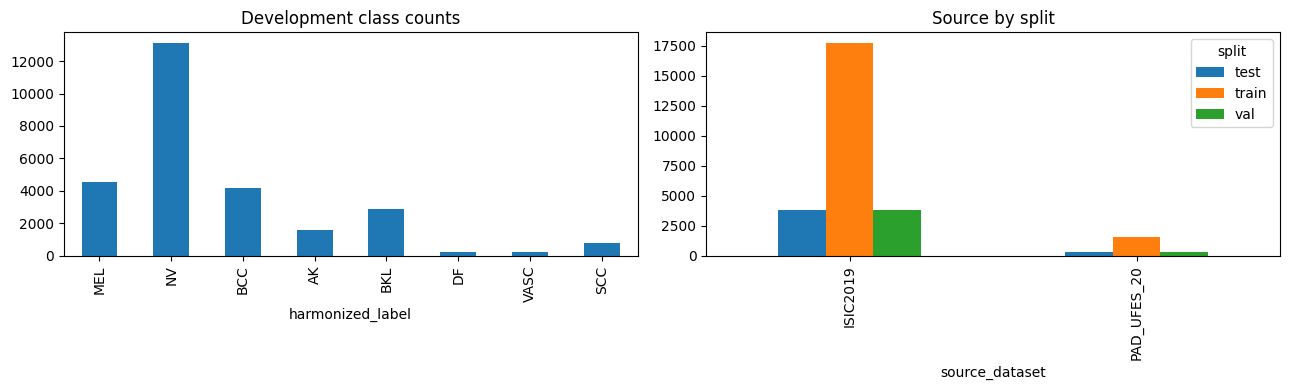


=== PIPELINE STATUS ===
OK   1_isic_extraction - 25,331/25,331 verified in Drive
OK   2_metadata_and_paths - ISIC 25,331 + PAD 2,298; all images located
OK   3_label_mapping - confirmed=True, unmapped=0
OK   4_fingerprints - 27,629 valid, 0 unreadable
OK   5_duplicate_audit - exact groups 65, near pairs 1861
OK   5b_geometric_verification - 150 verified of 1861; null max 128
OK   5c_fdr_calibration - q=0.05; accepted 348
OK   6_policy_gates - passed
OK   7_splits - {'train': 19341, 'val': 4131, 'test': 4129}
OK   8_final_verification - saved CSVs re-read and checked

PREPROCESSING COMPLETE and verified. Outputs in /content/drive/MyDrive/MAAI901_Group_Project/processed
{
  "development_images_in_splits": 27601,
  "quarantined": 28,
  "splits": {
    "train": 19341,
    "val": 4131,
    "test": 4129
  },
  "by_source": {
    "ISIC2019": 25327,
    "PAD_UFES_20": 2274
  }
}


In [ ]:
tr = dev.loc[dev.split == 'train', 'harmonized_label']; cnt = tr.value_counts().reindex(CLASSES, fill_value=0)
weights = {c: float(len(tr) / (len(CLASSES) * cnt[c])) for c in CLASSES}          # Calculate class weights using training data
save_json(PROCESSED/'class_weights.json', weights)
save_json(PROCESSED/'preprocessing_config.json', {'seed': SEED, 'class_order': CLASSES, 'development_sources': ['ISIC2019', 'PAD_UFES_20'],
    'external_only': 'DDI', 'split_fractions': frac, 'near_dup_hash_distance': NEAR_DUP_HASH_DISTANCE,
    'label_mapping_confirmed': CONFIRM_LABEL_MAPPING, 'pad_map': PAD_MAP,
    'portable_paths': 'use image_relpath (relative to the project folder) via processed/load_manifest.py; image_path is the owner\'s absolute path only',
    'normalization': 'architecture-specific; set in model notebooks from each model\'s official preprocessing',
    'disclosures': ['ISIC patient-level independence cannot be proven where patient IDs are missing (lesion_id used)',
                    'pHash near-duplicate search is heuristic', 'ISIC=dermoscopy, PAD=clinical smartphone: different domains',
                    'PAD->ISIC label mapping is a team decision; many PAD ACK/NEV/SEK labels are not biopsy-proven',
                    'Merging datasets does not remove skin-tone bias; ISIC has no skin-tone labels']})

# Check DDI files without including them in training
ddi = {'available': False, 'in_training': False}
for d in DDI_DIRS:
    if d.exists() and any(d.rglob('*.csv')):
        csv = max(d.rglob('*.csv'), key=lambda p: p.stat().st_size); cols_ = list(pd.read_csv(csv, nrows=0).columns)
        ddi = {'available': True, 'in_training': False, 'folder': str(d), 'metadata_csv': csv.name, 'columns': cols_,
               'skin_tone_columns': [c for c in cols_ if any(s in c.lower() for s in ['fitz', 'skin', 'tone'])]}; break
save_json(REPORTS/'ddi_readiness.json', ddi)
print('DDI:', 'metadata found (kept separate)' if ddi['available'] else 'not present yet - fine, nothing depends on it')

# Verify saved dataset files
chk = {s: pd.read_csv(PROCESSED/f'{s}.csv') for s in ['train', 'val', 'test']}
allv = pd.concat(chk.values(), ignore_index=True)
assert len(allv) == len(dev) and allv.image_uid.is_unique
assert not (set(chk['train'].group_id) & set(chk['val'].group_id)) and not (set(chk['train'].group_id) & set(chk['test'].group_id)) and not (set(chk['val'].group_id) & set(chk['test'].group_id))
assert all(os.path.isfile(p) for p in allv.image_path.sample(min(2000, len(allv)), random_state=0))
assert not allv.source_dataset.str.contains('DDI').any()
assert allv.image_relpath.notna().all() and not allv.image_relpath.str.startswith(('/', 'content', 'tmp')).any()
assert all((BASE/p).is_file() for p in allv.image_relpath.sample(min(2000, len(allv)), random_state=1))  # Check that image paths work
# Create a function to load dataset splits
(PROCESSED/'load_manifest.py').write_text('''"""Load a split with paths valid on THIS machine/account.
    from load_manifest import load_split
    train = load_split("train", "/content/drive/MyDrive/MAAI901_Group_Project")   # Project folder location
"""
from pathlib import Path
import os, pandas as pd

def load_split(split, project_root, check_sample=300):
    root = Path(project_root)
    df = pd.read_csv(root / "processed" / f"{split}.csv")
    df["image_path"] = [str(root / p) for p in df["image_relpath"]]         # Use paths relative to the project folder
    bad = [p for p in df["image_path"].sample(min(check_sample, len(df)), random_state=0) if not os.path.isfile(p)]
    if bad:
        raise FileNotFoundError(f"{len(bad)} sampled images not found, e.g. {bad[0]}. Check project_root / folder sharing.")
    return df
''')
summary = {'status': 'READY_FOR_MODEL_TRAINING', 'verified_at': time.strftime('%Y-%m-%d %H:%M:%S'),
           'development_images_in_splits': len(allv), 'quarantined': len(quarantine),
           'splits': {s: len(v) for s, v in chk.items()}, 'by_source': allv.source_dataset.value_counts().to_dict(),
           'by_class': allv.harmonized_label.value_counts().to_dict(), 'class_weights_train_only': weights,
           'fitzpatrick_known_in_development': int(allv.fitzpatrick.notna().sum()), 'ddi': ddi}
save_json(REPORTS/'final_preprocessing_summary.json', summary)
mark('8_final_verification', True, 'saved CSVs re-read and checked')

import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
allv.harmonized_label.value_counts().reindex(CLASSES).plot.bar(ax=ax[0], title='Development class counts')
pd.crosstab(allv.source_dataset, allv.split).plot.bar(ax=ax[1], title='Source by split'); plt.tight_layout()
plt.savefig(FIGURES/'development_distributions.png', dpi=150); plt.show()
print('\n=== PIPELINE STATUS ===')
for k, v in sorted(load_json(STATUS_PATH).items()): print(('OK  ' if v['ok'] else 'TODO'), k, '-', v['detail'])
print('\nPREPROCESSING COMPLETE and verified. Outputs in', PROCESSED)
print(json.dumps({k: summary[k] for k in ['development_images_in_splits', 'quarantined', 'splits', 'by_source']}, indent=2))


## Final Cross-Split Duplicate Review

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

HEAD, AUDIT_N = 30, 92

# Load possible duplicates with the highest matches first
q = pd.read_csv(
    REPORTS / 'near_duplicate_cross_split_pairs.csv'
).sort_values(
    'geom_inliers', ascending=False
).reset_index(drop=True)

# Load image paths
fin = pd.read_csv(
    PROCESSED / 'combined_development_final.csv',
    usecols=['image_uid', 'image_relpath']
)

path = {
    u: BASE / p
    for u, p in zip(fin.image_uid, fin.image_relpath)
}

# Select 30 top pairs and 92 random pairs for review
q['rank'] = np.arange(1, len(q) + 1)

head = q.head(HEAD).copy()
head['tier'] = 'A_ranked'

rest = q.iloc[HEAD:]
audit = rest.sample(
    n=min(AUDIT_N, len(rest)),
    random_state=SEED
).sort_values('rank').copy()
audit['tier'] = 'B_random'

work = pd.concat(
    [head, audit],
    ignore_index=True
)

work['decision'] = ''

# Save the review list
save_csv(
    work,
    PROCESSED / 'final_cross_split_audit_worklist.csv'
)

# Create side-by-side images for comparison
for s in range(0, len(work), 10):

    part = work.iloc[s:s + 10]

    fig, ax = plt.subplots(
        len(part),
        2,
        figsize=(7, 3.1 * len(part))
    )

    ax = np.atleast_2d(ax)

    for r, row in enumerate(part.itertuples()):

        for c, (u, label) in enumerate([
            (row.image_uid_a, row.label_a),
            (row.image_uid_b, row.label_b)
        ]):

            with Image.open(path[u]) as im:
                im.draft('RGB', (512, 512))
                ax[r, c].imshow(im.convert('RGB'))

            ax[r, c].axis('off')

            ax[r, c].set_title(
                f'#{row.rank} {row.split_pair} '
                f'{u.split(":")[-1][:18]} {label}',
                fontsize=8
            )

    plt.tight_layout()

    plt.savefig(
        FIGURES / f'final_audit_sheet_{s // 10 + 1:02d}.png',
        dpi=90
    )

    plt.close()

print(
    f'{len(work)} pairs selected for final audit.'
)

print(
    'Contact sheets saved to: '
    'outputs/figures/final_audit_sheet_*.png'
)

print(
    'Review worklist saved to: '
    'processed/final_cross_split_audit_worklist.csv'
)

122 pairs selected for final audit.
Contact sheets saved to: outputs/figures/final_audit_sheet_*.png
Review worklist saved to: processed/final_cross_split_audit_worklist.csv


## Near-Duplicate Image Review

In [ ]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from PIL import Image
HEAD, AUDIT_N = 30, 90
q = pd.read_csv(REPORTS/'near_duplicate_review_queue.csv')           # Load possible duplicates sorted by similarity
fin = pd.read_csv(PROCESSED/'combined_development_final.csv', usecols=['image_uid', 'image_relpath'])
path = {u: BASE/p for u, p in zip(fin.image_uid, fin.image_relpath)}
q['rank'] = np.arange(1, len(q) + 1)
head = q.head(HEAD).assign(tier='A_ranked_head')
rest = q.iloc[HEAD:]
audit = rest.sample(min(AUDIT_N, len(rest)), random_state=SEED).sort_values('rank').assign(tier='B_random_audit')
work = pd.concat([head, audit]); work['decision'] = ''
save_csv(work[['rank', 'tier', 'image_uid_a', 'image_uid_b', 'label_a', 'label_b', 'mean_abs_pixel_diff_32px', 'same_source_lesion_or_patient', 'decision']], PROCESSED/'review_worklist.csv')
def sheet(df, name, per=10):
    for s in range(0, len(df), per):
        part = df.iloc[s:s+per]; fig, ax = plt.subplots(len(part), 2, figsize=(7, 3.1*len(part))); ax = np.atleast_2d(ax)
        for r, row in enumerate(part.itertuples()):
            for c, (u, l) in enumerate([(row.image_uid_a, row.label_a), (row.image_uid_b, row.label_b)]):
                with Image.open(path[u]) as im:
                    im.draft('RGB', (512, 512)); ax[r, c].imshow(im.convert('RGB'))
                ax[r, c].axis('off'); ax[r, c].set_title(f'#{row.rank} {u.split(":")[1][:20]}  {l}', fontsize=8)
        plt.tight_layout(); plt.savefig(FIGURES/f'{name}_{s//per+1:02d}.png', dpi=90); plt.close()
sheet(work, 'review_sheet')
print(len(work), 'pairs ->', sorted(p.name for p in FIGURES.glob('review_sheet_*.png')))

120 pairs -> ['review_sheet_01.png', 'review_sheet_02.png', 'review_sheet_03.png', 'review_sheet_04.png', 'review_sheet_05.png', 'review_sheet_06.png', 'review_sheet_07.png', 'review_sheet_08.png', 'review_sheet_09.png', 'review_sheet_10.png', 'review_sheet_11.png', 'review_sheet_12.png']


## Near-Duplicate Review Decisions

In [ ]:
import time, shutil
CONFIDENT_DIFFERENT = []   # Ranks of image pairs confirmed as different
CONFIRMED_SAME      = {}   # Record confirmed duplicate pairs and reviewers

K = lambda a, b: tuple(sorted((a, b)))
work = pd.read_csv(PROCESSED/'review_worklist.csv', dtype=str).fillna('')
pair_of = {int(r): K(a, b) for r, a, b in zip(work['rank'], work.image_uid_a, work.image_uid_b)}
rev_path = PROCESSED/'reviewed_near_duplicates.csv'
rev = pd.read_csv(rev_path, dtype=str).fillna('')
assert {'image_uid_a', 'image_uid_b', 'decision'} <= set(rev.columns), 'unexpected review-file structure'
rev['decision'] = rev.decision.str.upper().str.strip()
assert rev.decision.isin(['', 'SAME', 'DIFFERENT']).all(), 'decision values must be blank/SAME/DIFFERENT'
pairs = [K(a, b) for a, b in zip(rev.image_uid_a, rev.image_uid_b)]
rev['image_uid_a'], rev['image_uid_b'] = [p[0] for p in pairs], [p[1] for p in pairs]
tri0 = pd.read_csv(REPORTS / 'near_duplicate_triage.csv')

have = {
    K(a, b)
    for a, b in zip(
        rev.image_uid_a,
        rev.image_uid_b
    )
}

add = [
    {
        'image_uid_a': k[0],
        'image_uid_b': k[1],
        'decision': ''
    }
    for k in (
        K(x, y)
        for x, y in zip(
            tri0.image_uid_a,
            tri0.image_uid_b
        )
    )
    if k not in have
]

n_before = len(rev)

rev = pd.concat(
    [
        rev,
        pd.DataFrame(
            add,
            columns=[
                'image_uid_a',
                'image_uid_b',
                'decision'
            ]
        )
    ],
    ignore_index=True
)
rev = (rev.assign(_h=rev.decision.ne('')).sort_values('_h', ascending=False, kind='stable')          # Keep one record per pair and preserve existing decisions
          .drop_duplicates(['image_uid_a', 'image_uid_b']).drop(columns='_h')
          .sort_values(['image_uid_a', 'image_uid_b']).reset_index(drop=True))
idx = {K(a, b): i for i, (a, b) in enumerate(zip(rev.image_uid_a, rev.image_uid_b))}

requests = [(r, 'DIFFERENT', 'visual review') for r in CONFIDENT_DIFFERENT if r not in CONFIRMED_SAME]
for r, who in CONFIRMED_SAME.items():
    if str(who).strip(): requests.append((r, 'SAME', str(who).strip()))
    else: print(f'  rank {r}: SAME needs reviewer name(s) in CONFIRMED_SAME - left undecided')
log, notes = [], defaultdict(list)
for rank, dec, who in requests:
    pair = pair_of.get(rank)
    if pair is None: notes['not in review_worklist.csv (skipped)'].append(rank); continue
    if pair not in idx: notes['not a current candidate pair (skipped)'].append(rank); continue
    cur = rev.at[idx[pair], 'decision']
    if cur == dec: notes['already recorded (no change)'].append(rank); continue
    if cur: notes[f'already {cur}; NOT overwritten (edit the file by hand if intended)'].append(rank); continue
    rev.at[idx[pair], 'decision'] = dec
    log.append({'rank': rank, 'image_uid_a': pair[0], 'image_uid_b': pair[1], 'decision': dec, 'reviewer': who, 'time': time.strftime('%Y-%m-%d %H:%M:%S')})
    if 'decided' in globals(): decided[pair] = dec          # Update the review decisions

for msg, ranks in notes.items(): print(f'  ranks {ranks}: {msg}')
if log or len(rev) != n_before:
    if rev_path.exists(): shutil.copy(rev_path, CACHE/f'reviewed_near_duplicates.backup_{time.strftime("%Y%m%d_%H%M%S")}.csv')
    save_csv(rev, rev_path)
if log:
    lp = REPORTS/'near_duplicate_review_log.csv'
    old = pd.read_csv(lp, dtype=str) if lp.exists() else pd.DataFrame()
    save_csv(pd.concat([old, pd.DataFrame(log)], ignore_index=True), lp)
print(f'Newly recorded: {len(log)} ({Counter(l["decision"] for l in log)}) | review file rows: {len(rev)} (was {n_before}) | backup in processed/_cache')
print('All recorded decisions:', rev.decision.value_counts().to_dict())

tri = pd.read_csv(REPORTS/'near_duplicate_triage.csv')
tri['k'] = [K(a, b) for a, b in zip(tri.image_uid_a, tri.image_uid_b)]
tri['decision'] = [rev.at[idx[k], 'decision'] if k in idx else '' for k in tri.k]
unres = tri[tri.decision.eq('')]
print(f'Unresolved near-duplicate pairs: {len(unres)} of {len(tri)} ({int(unres.label_conflict.sum())} with conflicting labels) -> stay linked in one split, NOT quarantined')
print(f'SAME + conflicting labels (will be quarantined at Stage 6): {int(((tri.decision == "SAME") & tri.label_conflict).sum())}')

fin_p = PROCESSED/'combined_development_final.csv'
if fin_p.exists():
    fin = pd.read_csv(fin_p, usecols=['image_uid', 'group_id', 'split'])
    gs = fin.groupby('group_id').agg(n=('image_uid', 'size'), n_splits=('split', 'nunique'))
    print(f'Groups in CURRENT split files: {len(gs):,} | multi-image groups: {int((gs.n > 1).sum())} | largest group: {int(gs.n.max())} images | groups spanning >1 split: {int((gs.n_splits > 1).sum())}')
    print('  (rerun this cell after Stage 8 to see the group sizes of the regenerated splits)')
print('\nNEXT: if you changed nothing about #1 (still undecided) or marked it DIFFERENT -> no SAME pair exists: keep the current splits, do not rerun.')
print('      if #1 (or any pair) is now SAME -> run Stage 6, then Stage 7, then Stage 8 (never 1-5). After a runtime restart: run setup, then Run all.')

Newly recorded: 0 (Counter()) | review file rows: 1861 (was 1861) | backup in processed/_cache
All recorded decisions: {'': 1861}
Unresolved near-duplicate pairs: 1861 of 1861 (650 with conflicting labels) -> stay linked in one split, NOT quarantined
SAME + conflicting labels (will be quarantined at Stage 6): 0
Groups in CURRENT split files: 15,297 | multi-image groups: 5595 | largest group: 31 images | groups spanning >1 split: 0
  (rerun this cell after Stage 8 to see the group sizes of the regenerated splits)

NEXT: if you changed nothing about #1 (still undecided) or marked it DIFFERENT -> no SAME pair exists: keep the current splits, do not rerun.
      if #1 (or any pair) is now SAME -> run Stage 6, then Stage 7, then Stage 8 (never 1-5). After a runtime restart: run setup, then Run all.


## Duplicate Verification — Additional Checks

In [ ]:
import networkx as nx
PAIRS = [('0012290', '0013594'), ('0015986', '0015987'), ('0025226', '0030074')]
g = pd.read_csv(REPORTS/'near_duplicate_geometric_verification.csv'); nl = pd.read_csv(CACHE/'geom_null_scores.csv')
fin = pd.read_csv(PROCESSED/'combined_development_final.csv', usecols=['image_uid', 'split', 'group_id']).set_index('image_uid')
rows = []
for x, y in PAIRS:
    m = g[(g.image_uid_a.str.contains(x) & g.image_uid_b.str.contains(y)) | (g.image_uid_a.str.contains(y) & g.image_uid_b.str.contains(x))]
    if m.empty: rows.append({'pair': f'{x}/{y}', 'in_candidates': False}); continue
    r = m.iloc[0]; a, b = r.image_uid_a, r.image_uid_b
    rows.append({'pair': f'{x}/{y}', 'in_candidates': True, 'inliers': int(r.inliers), 'verified': bool(r.verified),
                 'split_a': fin.split.get(a, 'quarantined'), 'split_b': fin.split.get(b, 'quarantined'),
                 'same_group': (a in fin.index and b in fin.index and fin.group_id[a] == fin.group_id[b])})
print(pd.DataFrame(rows).to_string(index=False))
Gc = nx.Graph(list(zip(g.image_uid_a, g.image_uid_b))); comp = {u: i for i, c in enumerate(nx.connected_components(Gc)) for u in c}
top = nl.sort_values('inliers', ascending=False).head(10).copy()
top['same_candidate_cluster'] = [comp.get(a, -1) == comp.get(b, -2) for a, b in zip(top.image_uid_a, top.image_uid_b)]
print(f'\nNull max = {int(nl.inliers.max())}; 99th pct = {nl.inliers.quantile(.99):.0f}. Top-10 null pairs:')
print(top[['inliers', 'same_candidate_cluster']].to_string(index=False))
print(f'Verified: {int(g.verified.sum())} | candidates above the null 99th pct but NOT verified: {int(((g.inliers > nl.inliers.quantile(.99)) & ~g.verified).sum())}')

           pair  in_candidates  inliers  verified split_a split_b  same_group
0012290/0013594           True      179      True     val     val        True
0015986/0015987           True       88     False   train    test       False
0025226/0030074           True       53     False    test    test       False

Null max = 128; 99th pct = 21. Top-10 null pairs:
 inliers  same_candidate_cluster
     128                   False
     106                   False
      82                   False
      76                   False
      68                   False
      63                   False
      61                   False
      52                   False
      48                   False
      48                   False
Verified: 150 | candidates above the null 99th pct but NOT verified: 202


## Duplicate Verification — FDR and Split Checks

In [ ]:
PAIRS = [('0012290','0013594'), ('0015986','0015987'), ('0025226','0030074')]
g = pd.read_csv(REPORTS/'near_duplicate_geometric_verification.csv')
f = pd.read_csv(PROCESSED/'combined_development_final.csv', usecols=['image_uid','split','group_id']).set_index('image_uid')
for x, y in PAIRS:
    m = g[(g.image_uid_a.str.contains(x) & g.image_uid_b.str.contains(y)) | (g.image_uid_a.str.contains(y) & g.image_uid_b.str.contains(x))]
    if m.empty: print(x, y, '| not a candidate pair'); continue
    m = m.iloc[0]; a, b = m.image_uid_a, m.image_uid_b
    print(x, y, '| inliers', int(m.inliers), '| fdr_pass', bool(m.fdr_pass), '| strict', bool(m.verified), '| splits', f.split.get(a, 'quarantined'), f.split.get(b, 'quarantined'), '| same_group', a in f.index and b in f.index and f.group_id[a] == f.group_id[b])

0012290 0013594 | inliers 179 | fdr_pass True | strict True | splits test test | same_group True
0015986 0015987 | inliers 88 | fdr_pass True | strict False | splits train train | same_group True
0025226 0030074 | inliers 53 | fdr_pass True | strict False | splits train train | same_group True


## Visual Comparison of Duplicate Image Pair 30

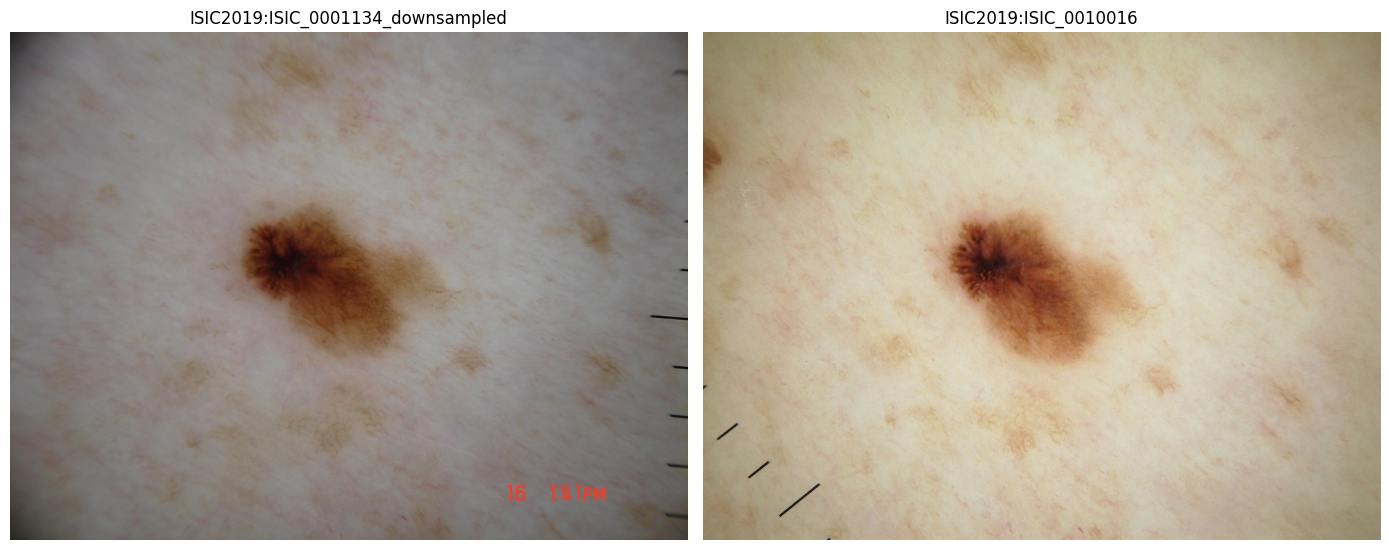

In [ ]:
row = work[work['rank'] == 30].iloc[0]

fig, ax = plt.subplots(1, 2, figsize=(14, 7))

for i, uid in enumerate([row.image_uid_a, row.image_uid_b]):
    with Image.open(path[uid]) as im:
        ax[i].imshow(im.convert('RGB'))
    ax[i].set_title(uid)
    ax[i].axis('off')

plt.tight_layout()
plt.show()

## Confirming Duplicate Image Pair 30

In [ ]:
# Confirm duplicate pair 30

row = work[work['rank'] == 30].iloc[0]

a = row.image_uid_a
b = row.image_uid_b
key = tuple(sorted((a, b)))

assert 'decided' in globals(), "Review decisions are not loaded"
assert 'near_link' in globals(), "Near-duplicate candidates are not loaded"

# Save the duplicate decision
decided[key] = 'SAME'
# Save the confirmed duplicate decision
review_file = PROCESSED / 'reviewed_near_duplicates.csv'
review = pd.read_csv(review_file, dtype=str).fillna('')

mask = (
    ((review.image_uid_a == a) & (review.image_uid_b == b)) |
    ((review.image_uid_a == b) & (review.image_uid_b == a))
)

if mask.any():
    review.loc[mask, 'decision'] = 'SAME'
else:
    review = pd.concat([
        review,
        pd.DataFrame([{
            'image_uid_a': a,
            'image_uid_b': b,
            'decision': 'SAME'
        }])
    ], ignore_index=True)

save_csv(review, review_file)

# Keep both images in the same group
if key not in near_link:
    near_link = list(near_link)
    near_link.append(key)

print("Confirmed duplicate recorded:")
print(a)
print(b)
print("Decision:", decided[key])
print("Will be grouped:", is_link_pair(key))

Confirmed duplicate recorded:
ISIC2019:ISIC_0001134_downsampled
ISIC2019:ISIC_0010016
Decision: SAME
Will be grouped: True


### Final Dataset Verification

After confirming duplicate pair 30, the duplicate review and dataset splitting steps need to be updated before saving the final dataset.

The order is:

1. Confirm and save the duplicate decision.
2. Update the duplicate audit (Cells 5, 5A and 5B).
3. Run Cell 6 to update the cleaned dataset.
4. Run Cell 7 to regenerate the dataset splits.
5. Run Cell 8 to verify the final datasets.
6. Save the verified splits in `frozen_v1`.

## Saving the Final Dataset Splits

In [ ]:
# Save final dataset splits

from pathlib import Path
import shutil, hashlib, json

freeze = BASE / 'processed' / 'frozen_v1'
freeze.mkdir(parents=True, exist_ok=True)

files = [
    'train.csv',
    'val.csv',
    'test.csv',
    'combined_development_final.csv'
]

manifest = {}

for name in files:
    src = PROCESSED / name
    dst = freeze / name
    shutil.copy2(src, dst)
    manifest[name] = hashlib.sha256(dst.read_bytes()).hexdigest()

# Save the confirmed duplicate pair
decision_file = freeze / 'confirmed_duplicate_30.json'
decision_file.write_text(json.dumps({
    'image_uid_a': a,
    'image_uid_b': b,
    'decision': 'SAME',
    'reviewed_by': 'Two independent reviewers'
}, indent=2))

(freeze / 'checksums.json').write_text(
    json.dumps(manifest, indent=2)
)

print('Frozen dataset saved:', freeze)
print('Files:', files)

Frozen dataset saved: /content/drive/MyDrive/MAAI901_Group_Project/processed/frozen_v1
Files: ['train.csv', 'val.csv', 'test.csv', 'combined_development_final.csv']
